# TIB pinned-snapshot EDA and qualification evidence

Executed on 2026-10-19. This notebook verifies and renders saved CPU audit artifacts; the CLI performed the full 9,103-record canonical/tokenizer scan. It does not rerun that scan or generate summaries. Raw text remains in ignored local storage. The old 120/9-pilot evidence is unchanged.

Scope: local private noncommercial use subject to per-record rights; no source/reference redistribution or external generation API use is authorized. A/B/C are conservative research usability decisions, not gold factuality labels.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from experiments.scripts.tib_model_benchmark_qualification_inputs import validate_receipts
root = Path('research-data/tib-qualification-261019-1703')
registry = Path('experiments/registry/datasets/tib-text-model-benchmark-v1/qualification-261019-1703')
validate_receipts(root, registry)
def load(path): return json.loads(path.read_text(encoding='utf-8'))
eda = load(root / 'eda/summary.json')
cohort = load(registry / 'development_cohort.json')
assert eda['records'] == 9103 and not cohort['generation_executed']
display(pd.DataFrame(cohort['counts']).T)
print('Full pinned frame = 9103. Rights + content eligibility and post-exposure counts are separate.')

,source,data_eligible,after_exposure,exposure_reasons
train,7282,4215,4213,{'historical_120_or_9_pilot': 2}
valid,910,532,464,{'historical_120_or_9_pilot': 68}
test,911,523,523,{}


Full pinned frame = 9103. Rights + content eligibility and post-exposure counts are separate.


In [2]:
table = []
for split, data in eda['counts'].items():
    for metric in ('source_words','reference_words','compression_ratio'):
        table.append({'split':split,'metric':metric,**data[metric]})
display(pd.DataFrame(table))
print('Compression N excludes empty references; lengths use canonical whitespace words.')

,split,metric,n,p50,p90,p95,max
0,train,source_words,7282,4702.000000,8961.900000,10517.550000,30044.000000
1,train,reference_words,7282,110.000000,275.000000,346.000000,909.000000
2,train,compression_ratio,7276,41.893915,167.212158,259.955780,7589.000000
3,valid,source_words,910,4566.500000,9026.200000,10731.100000,27966.000000
4,valid,reference_words,910,110.000000,253.100000,311.850000,771.000000
5,valid,compression_ratio,909,42.405660,145.275765,241.111444,1809.666667
6,test,source_words,911,4728.000000,9005.000000,10411.500000,20107.000000
7,test,reference_words,911,106.000000,269.000000,345.500000,787.000000
8,test,compression_ratio,910,42.924985,175.070213,279.150625,1778.750000


Compression N excludes empty references; lengths use canonical whitespace words.


In [3]:
for split, data in eda['counts'].items():
    display(pd.DataFrame(data['source_native_tokens']).T.assign(split=split))
    display(pd.DataFrame({'genre':pd.Series(data['genre'])}).fillna(0))
    display(pd.DataFrame({'subject':pd.Series(data['subject'])}).fillna(0))
    print(split, 'language:', data['language'], 'observed sidecar/technical flags:', data['anomalies'])
print('Native source counts exclude special tokens. Window lower bounds omit wrappers/overlap/reduction and do not establish safe T4 capacity.')

,n,p50,p90,p95,max,split
bart,7282.0,5596.0,10770.0,12590.85,37558.0,train
led,7282.0,5596.0,10770.0,12590.85,37558.0,train
qwen3,7282.0,5584.5,10777.5,12555.80,37455.0,train


,genre
Lecture,665
Conference/Talk,6364
Workshop/Interactive Format\nLecture,80
Webinar/Tutorial,109
Conference/Talk\nLecture,25
Lecture\nConference/Talk,21
Conference/Talk\nWorkshop/Interactive Format,13
Conference/Talk\nLecture\nWorkshop/Interactive Format,3
Lecture\nConference/Talk\nResearch Data\nVideo Abstract,1
UNKNOWN,1


,subject
Engineering,46
Computer Science,5872
Chemistry,279
Mathematics,292
Economics and Social Sciences,56
Physics,200
Mathematics\nPhysics,88
Architecture,22
Information Science,112
Linguistics,76


train language: {'en': 7282} observed sidecar/technical flags: {'transcript_segment_mismatch': 358, 'replacement_character_no_automatic_repair': 26, 'overlapping_segment_time': 48, 'invalid_segment_time': 83, 'empty_reference': 6}


,n,p50,p90,p95,max,split
bart,910.0,5470.5,10842.7,12724.30,34599.0,valid
led,910.0,5470.5,10842.7,12724.30,34599.0,valid
qwen3,910.0,5477.5,10901.4,12706.05,34564.0,valid


,genre
Conference/Talk,810
Lecture,71
Webinar/Tutorial,10
Workshop/Interactive Format\nLecture,11
Conference/Talk\nLecture,2
Conference/Talk\nWorkshop/Interactive Format,2
Lecture\nConference/Talk,3
Conference/Talk\nLecture\nWorkshop/Interactive Format,1


... (2 outputs left out)

,n,p50,p90,p95,max,split
bart,911.0,5618.0,10822.0,12468.0,23118.0,test
led,911.0,5618.0,10822.0,12468.0,23118.0,test
qwen3,911.0,5564.0,10895.0,12467.0,23001.0,test


,genre
Conference/Talk,792
Lecture,91
Webinar/Tutorial,18
Conference/Talk\nWorkshop/Interactive Format,3
Workshop/Interactive Format\nLecture,5
Conference/Talk\nLecture,1
Lecture\nConference/Talk,1


,subject
Computer Science,728
Chemistry,34
Mathematics,41
Information Science,15
Physics,22
Linguistics,14
Engineering,7
Architecture,6
Mathematics\nPhysics,9
Economics and Social Sciences,8


test language: {'en': 911} observed sidecar/technical flags: {'transcript_segment_mismatch': 39, 'invalid_segment_time': 11, 'overlapping_segment_time': 10, 'empty_reference': 1, 'unordered_segment_time': 1}
Native source counts exclude special tokens. Window lower bounds omit wrappers/overlap/reduction and do not establish safe T4 capacity.


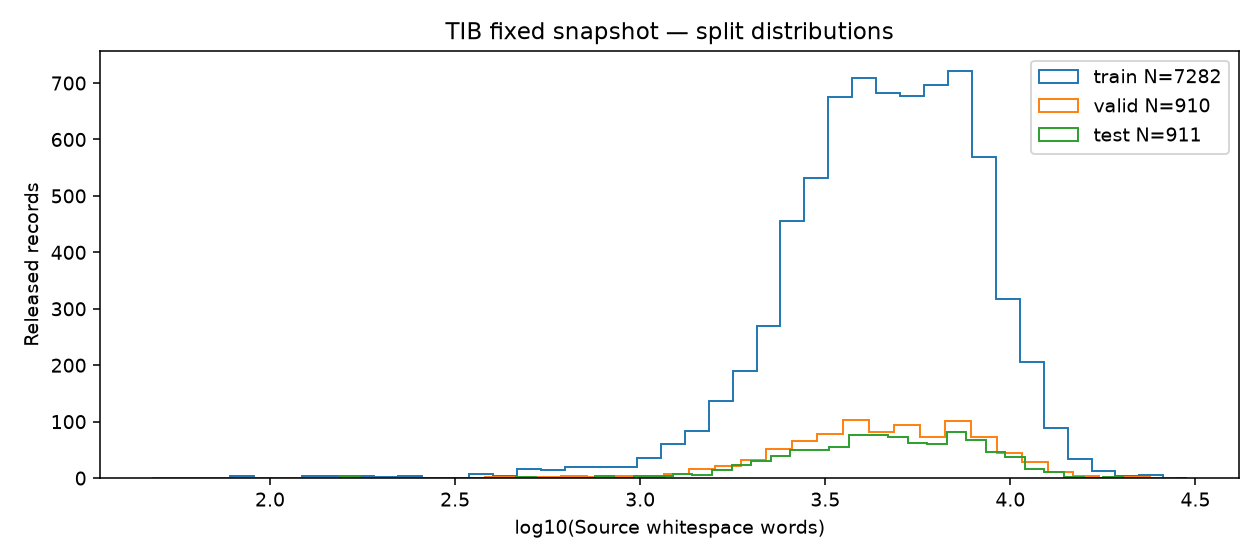

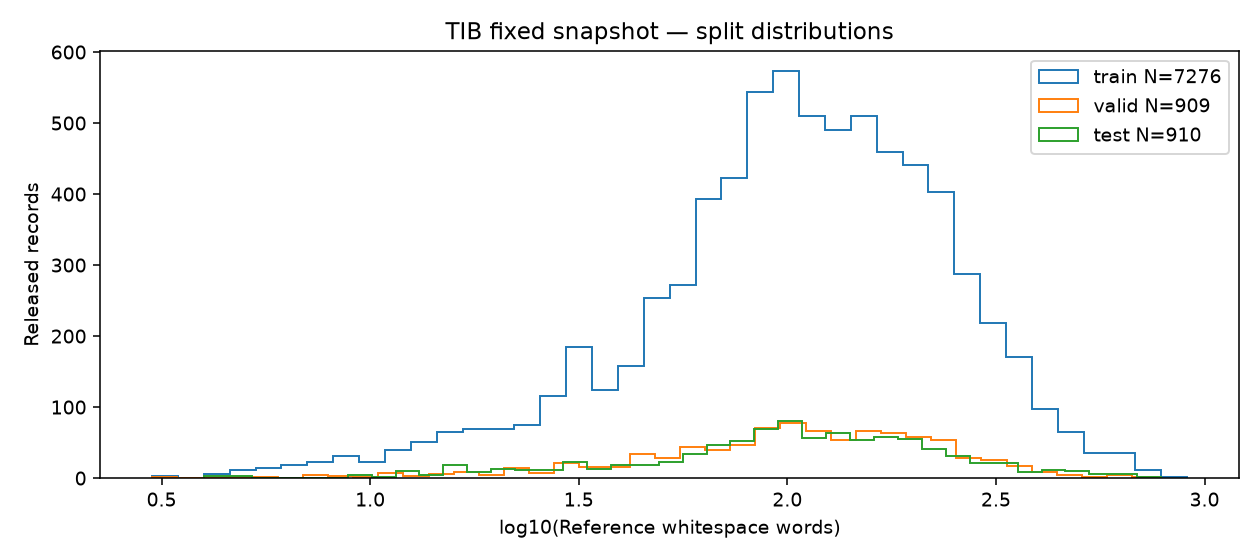

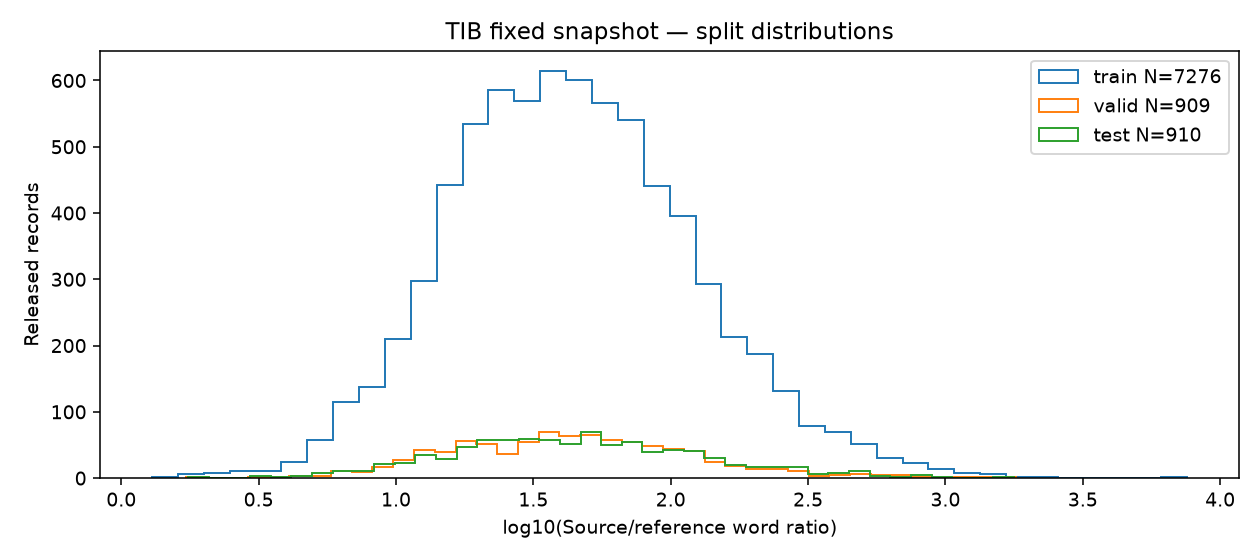

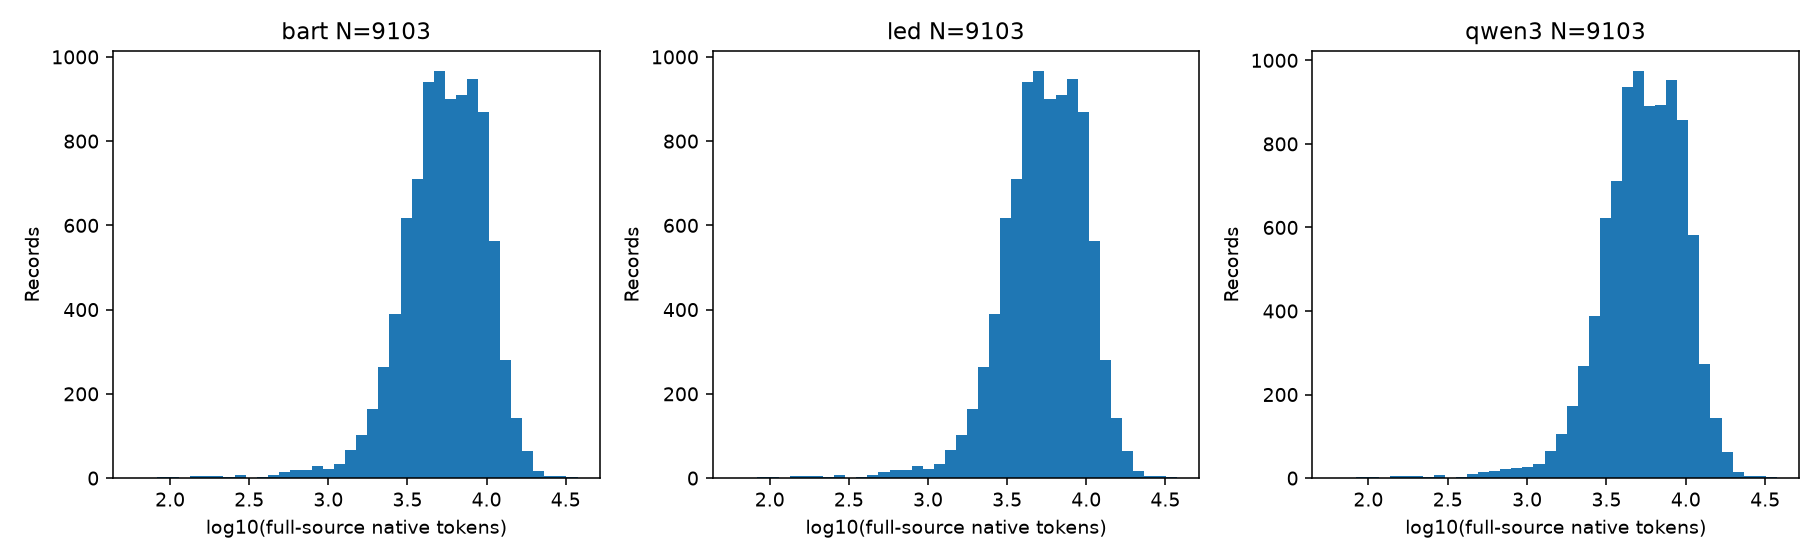

In [4]:
for name in ('source_words','reference_words','compression_ratio','native_token_tails'):
    display(Image(filename=str(root / 'eda/figures' / (name+'.png'))))

In [5]:
display(load(registry / 'reference_summary.json'))
display(load(registry / 'rights_summary.json')['counts_by_split'])
group = load(registry / 'source_group_summary.json')
display({key:value for key,value in group.items() if key not in ('known_three_edges','previous_attempts')})
print('225 historical flags reviewed; 226 casefold-reuse members include an extra structurally excluded legacy row. All reviewed cases remain uncertain B. A=0: A-only sensitivity unavailable.')
print('Approximate source-group retrieval has unknown recall. Additive replay records the original runtime/file-identity limitation; no exhaustive independence claim.')

{'policy_version': 'tib-reference-usability-v1-261019-1703',
 'policy_sha256': '5562791aba7b8125bba765f58388d86f1ccac3eccfa05ed5cd95bdf963a789fd',
 'revision': 'e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee',
 'source_count': 9103,
 'labels': {'B': 9095, 'C': 8},
 'by_split': {'train': {'B': 7276, 'C': 6},
  'valid': {'B': 909, 'C': 1},
  'test': {'B': 910, 'C': 1}},
 'legacy_structural_eligible': 9002,
 'legacy_empty_after_structure': 8,
 'legacy_reused_flags': 225,
 'legacy_reused_groups': 18,
 'legacy_broad_pool': 8769,
 'current_case_sensitive_reused_flags': 224,
 'current_case_sensitive_reused_groups': 17,
 'legacy_only_reused_ids': ['train:4447', 'train:7123'],
 'current_only_reused_ids': ['train:5322'],
 'targeted_adjudication_complete': True,
 'A_only_sensitivity_available': False,
 'cohort_seal_ready': False,
 'rights_granted': False,
 'historical_reconciliation': 'legacy structural pool + casefold reference groups; new flags use all rows + NFC case-sensitive references',
 'raw_tex

{'train': {'total': 7282,
  'source_status': {'conditional': 4949, 'hold': 2333},
  'source_allowed': 4949,
  'reference_allowed': 4468,
  'source_and_reference_allowed': 4215},
 'valid': {'total': 910,
  'source_status': {'conditional': 616, 'hold': 294},
  'source_allowed': 616,
  'reference_allowed': 568,
  'source_and_reference_allowed': 532},
 'test': {'total': 911,
  'source_status': {'conditional': 606, 'hold': 305},
  'source_allowed': 606,
  'reference_allowed': 556,
  'source_and_reference_allowed': 523}}

{'policy_sha256': '71e2748b8347b573e5e63a5a2c1915e6ea1b2afb1d39bc2d4c14d335978d6f4f',
 'records': 9103,
 'split_counts': {'train': 7282, 'valid': 910, 'test': 911},
 'candidate_pairs_checked': 2854654,
 'historical_pairs_checked': 2658,
 'accepted_edges': 22,
 'groups': 9082,
 'non_singleton_records': 37,
 'component_record_size_distribution': {'1': 9066, '2': 24, '3': 9, '4': 4},
 'omitted_common_sketch_postings': 8,
 'known_three_edges_reproduced': True,
 'near_recall': 'unknown; sketch retrieval not exhaustive; known-dependent grouping only',
 'automatic_exclusions': 0,
 'runtime_seconds': 370.11,
 'fingerprint_bytes': 391793384,
 'script_sha256': '7fb4c427c50ec8551e363c0568d48c430c7dcfb786a911ed8124c8e223c51252',
 'accepted_reason_counts': {'confirmed_near_transcript': 22},
 'accepted_edge_split_counts': {'train/train': 13,
  'train/valid': 4,
  'test/train': 4,
  'test/valid': 1},
 'component_size_distribution': {'1': 9066, '2': 12, '3': 3, '4': 1},
 'largest_components': [['train

225 historical flags reviewed; 226 casefold-reuse members include an extra structurally excluded legacy row. All reviewed cases remain uncertain B. A=0: A-only sensitivity unavailable.
Approximate source-group retrieval has unknown recall. Additive replay records the original runtime/file-identity limitation; no exhaustive independence claim.


In [6]:
display({k:cohort[k] for k in ('state','pilot_n','selection_n','pilot_quotas','selection_quotas','source_word_cutpoints','selection_fallback','staged_pilot_ids','final_test_sealed','blocked_runtime_gates')})
display(load(registry / 'compute_preflight.json'))
display(load(registry / 'eda_gap_matrix.json'))
assert len(cohort['selected_ids']['pilot']) == 40 and len(cohort['selected_ids']['selection']) == 300
assert not set(cohort['selected_groups']['pilot']) & set(cohort['selected_groups']['selection'])
print('No new model result or model selection. W_global UNSET; 523 is the eligible test frame, not a final benchmark seal.')

{'state': 'development_ids_sealed_no_generation_authorized',
 'pilot_n': 40,
 'selection_n': 300,
 'pilot_quotas': {'short': 13, 'medium': 12, 'long': 15},
 'selection_quotas': {'short': 100, 'medium': 90, 'long': 110},
 'source_word_cutpoints': [3447, 5891],
 'selection_fallback': False,
 'staged_pilot_ids': ['valid:644', 'valid:341', 'valid:886'],
 'final_test_sealed': False,
 'blocked_runtime_gates': ['scorer_ready',
  'candidate_profiles',
  'T4_measured_capacity',
  'compute_storage_retry_budgets']}

{'observed_gpu': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'memory_MiB': 6141,
 'driver': '610.88',
 'observation_command': 'nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv,noheader',
 'T4_verified': False,
 'inference_executed': False,
 'runtime_blockers': ['scorer_ready',
  'candidate_profiles',
  'T4_measured_capacity',
  'compute_storage_retry_budgets'],
 'global_output_word_cap': None}

{'state': 'executed_data_eda_profile_dependent_gaps_open',
 'records': 9103,
 'covered': {'canonical_raw_normalized_hash_offsets': 'eda/canonical_records.jsonl.gz; all native splits',
  'source_reference_compression_quantiles': 'eda/summary.json; p50/p90/p95/max; zero denominators excluded explicitly',
  'genre_subject_language_segment_flags': 'eda/summary.json; split counts, observed metadata only',
  'native_source_token_counts': 'three pinned tokenizers; full canonical source, special tokens excluded',
  'reference_policy': 'A=0/B=9095/C=8; historical225 flags reviewed as uncertain B; no gold claim',
  'source_groups': '22 confirmed edges, 9082 components; approximate retrieval, recall unknown',
  'rights_and_exposure': '9103 ledger decisions; data and role denominators reported separately',
  'development_roles': '40 pilot/300 selection sealed; known group and ID overlap zero'},
 'open': {'wrapper_aware_context_and_windows': 'P4 frozen prompts, special tokens, output reserve, overl

No new model result or model selection. W_global UNSET; 523 is the eligible test frame, not a final benchmark seal.
